In [ ]:
# Copyright 2026 Google LLC
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#     https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# Building AI Agents with BigQuery and SQL: the Brooklyn 311 agent

In this notebook, you build a data agent that answers questions about NYC 311 service requests in Brooklyn, using SQL and a few API calls.

| Step | What you do |
| :--- | :--- |
| 1 | Copy Brooklyn's 311 requests from a BigQuery public dataset into your project. |
| 2 | Use AI functions in SQL: `AI.CLASSIFY`, `AI.IF`, `AI.GENERATE`, `AI.AGG`, and `AI.FORECAST`. |
| 3 | Create a data agent with the Conversational Analytics API, including instructions, glossary terms, and verified queries. |
| 4 | Chat with your agent from Python, and inspect the SQL it writes. |
| 5 | Publish your agent to Gemini Enterprise. |
| 6 | Bonus: call your agent from an ADK agent, and connect ADK to the BigQuery remote MCP server. |

**About the data:** the NYC 311 service requests come from [NYC Open Data](https://opendata.cityofnewyork.us/). The BigQuery public dataset `bigquery-public-data.new_york_311.311_service_requests` ends in November 2021, so in this notebook, "recent" means late 2021.

## Before you begin

**You need a Google Cloud project with billing enabled**, and these IAM roles on it. Project Owners have most of these permissions already.

| To do this | You need these roles |
| :--- | :--- |
| Run queries and AI functions | BigQuery User (`roles/bigquery.user`), BigQuery Job User (`roles/bigquery.jobUser`), and Agent Platform User (`roles/aiplatform.user`) |
| Create and chat with data agents | Gemini Data Analytics Data Agent Creator (`roles/geminidataanalytics.dataAgentCreator`), Gemini for Google Cloud User (`roles/cloudaicompanion.user`), and BigQuery Studio User (`roles/bigquery.studioUser`) |
| Use the BigQuery MCP server (Step 6, optional) | MCP Tool User (`roles/mcp.toolUser`) and BigQuery Data Viewer (`roles/bigquery.dataViewer`) |

To publish your agent to Gemini Enterprise (Step 5, optional), you also need a Gemini Enterprise app where you're an admin, or an admin who can help.

**Costs.** This notebook uses billable Google Cloud services: BigQuery, AI functions in BigQuery (which call Gemini), and the Conversational Analytics API. It processes around 20 GB of BigQuery data in total, most of it to copy the public table once. BigQuery on-demand pricing includes 1 TiB of query processing per month at no cost. The AI functions make a few thousand short Gemini calls. For details, see [BigQuery pricing](https://cloud.google.com/bigquery/pricing). When you're done, run the **Clean up** cell at the end.

**How to run this notebook**

- **Colab:** go to [colab.research.google.com](https://colab.research.google.com), click **File** > **Upload notebook**, and choose this file.
- **BigQuery Studio:** in the Google Cloud console, go to **BigQuery**. In the **Explorer** pane, expand your project, click **View actions** next to **Notebooks**, and then click **Upload notebook**.
- **Local Jupyter:** run `gcloud auth application-default login`, and then open the notebook.

## Set up your environment

### Install packages

In [1]:
%pip install --upgrade --quiet "google-cloud-bigquery[pandas]" google-cloud-geminidataanalytics "google-adk[mcp]>=2.7.0"
%pip install --quiet matplotlib altair

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### Restart the runtime

To use the new packages, restart the runtime. In Colab, the next cell restarts it for you. In other environments, restart the kernel yourself.

> **Note:** Wait for the restart to finish before you run the next cell.

In [2]:
import sys

if "google.colab" in sys.modules:
    import IPython

    app = IPython.Application.instance()
    app.kernel.do_shutdown(True)

### Authenticate

In Colab, sign in with a Google account that has access to your project. BigQuery Studio and local Jupyter use the credentials you already have.

In [3]:
import sys

if "google.colab" in sys.modules:
    from google.colab import auth

    auth.authenticate_user()

### Set your project and names

Set `PROJECT_ID` to your Google Cloud project ID. The other defaults work as they are.

In [ ]:
import os

import google.auth

PROJECT_ID = "[your-project-id]"  # @param {type: "string", placeholder: "[your-project-id]", isTemplate: true}
if not PROJECT_ID or PROJECT_ID == "[your-project-id]":
    PROJECT_ID = os.environ.get("GOOGLE_CLOUD_PROJECT") or google.auth.default()[1]
if not PROJECT_ID:
    raise ValueError("Set PROJECT_ID to the ID of your Google Cloud project.")

BQ_LOCATION = "US"  # The NYC 311 public dataset is in the US multi-region.
DATASET = "bk_data"  # @param {type: "string"}

# Data agent ID: lowercase letters, numbers, and hyphens.
AGENT_ID = "brooklyn-311-analyst"  # @param {type: "string"}
# "global" is the default endpoint. Use "us" if you need US data residency.
AGENT_LOCATION = "global"  # @param ["global", "us"]

# How many distinct resolution notes to classify with Gemini in Step 2c.
# Lower it (for example, to 500) for a faster, cheaper run.
MAX_DISTINCT_NOTES = 2000  # @param {type: "integer"}

T_RAW = f"`{PROJECT_ID}.{DATASET}.brooklyn_311`"
T_CB = f"`{PROJECT_ID}.{DATASET}.brooklyn_community_boards`"
T_OUT = f"`{PROJECT_ID}.{DATASET}.resolution_outcomes`"
T_VIEW = f"`{PROJECT_ID}.{DATASET}.brooklyn_311_enriched`"

print(f"Project:    {PROJECT_ID}")
print(f"Dataset:    {DATASET} ({BQ_LOCATION})")
print(f"Data agent: {AGENT_ID} ({AGENT_LOCATION})")

Project:    lakehouse-demos
Dataset:    bk_data (US)
Data agent: brooklyn-311-analyst (global)


### Enable the APIs

This cell enables BigQuery, the Agent Platform API (which AI functions use to call Gemini), the Conversational Analytics API (`geminidataanalytics`), and Gemini for Google Cloud (`cloudaicompanion`). Newly enabled APIs can take a minute or two to start working.

In [6]:
!gcloud services enable bigquery.googleapis.com aiplatform.googleapis.com geminidataanalytics.googleapis.com cloudaicompanion.googleapis.com --project={PROJECT_ID}

Operation "operations/acat.p2-704119545530-c23b986e-404f-4016-b36f-899ec83cb38e" finished successfully.


### Create BigQuery helpers

`run_sql()` runs a query, caps how many bytes it can bill, prints how much data it processed, and returns the results as a DataFrame. `estimate_gb()` uses a free dry run to check a query's size before you run it.

In [35]:
def run_sql(sql, max_gb=15, **params):
    """Runs a query and returns the results as a DataFrame.

    Prints the GB processed and, for queries that call AI functions, the rows
    each function processed. max_gb caps the bytes billed, so a mistake can't
    scan more than you expect. Keyword arguments become STRING query
    parameters (@name in the SQL).
    """
    job_config = bigquery.QueryJobConfig(
        maximum_bytes_billed=int(max_gb * 1e9),
        query_parameters=[
            bigquery.ScalarQueryParameter(name, "STRING", value)
            for name, value in params.items()
        ],
    )
    job = bq.query(sql, job_config=job_config)
    df = job.to_dataframe()
    print(f"Processed {(job.total_bytes_processed or 0) / 1e9:.2f} GB")
    print_ai_usage(job)
    return df if len(df.columns) else None  # DDL statements return no columns.


def print_ai_usage(job):
    """Prints per-function AI stats for a finished query job.

    The BigQuery API reports rows, cache hits, and failures for each AI
    function, but not tokens. The BigQuery console shows the job's token
    counts under Job information, so this also prints a link to the job.
    """
    # The client library has no property for genAiStats yet, so read the raw
    # job resource (statistics.query.genAiStats in the REST API).
    query_stats = job._properties.get("statistics", {}).get("query", {})
    function_stats = query_stats.get("genAiStats", {}).get("functionStats", [])
    if not function_stats:
        return
    for stats in function_stats:
        rows = int(stats.get("numProcessedRows", 0))
        cached = int(stats.get("cacheStats", {}).get("numCacheHitRows", 0))
        failed = int(stats.get("errorStats", {}).get("numFailedRows", 0))
        print(
            f"{stats.get('functionName', 'AI function')}: {rows:,} rows processed "
            f"({cached:,} served from cache, {failed:,} failed)"
        )
    print(
        "Token counts (Job information): https://console.cloud.google.com/bigquery"
        f"?project={job.project}&j=bq:{job.location}:{job.job_id}&page=queryresults"
    )

## Step 1: Build the demo dataset

Copy Brooklyn's 311 requests from January 2019 onward into your project. A smaller copy that's partitioned by day and clustered by complaint type makes every later query faster and cheaper, including the queries your agent writes.

In [8]:
dataset = bigquery.Dataset(f"{PROJECT_ID}.{DATASET}")
dataset.location = BQ_LOCATION
dataset.description = "GDG DevFest Brooklyn demo: a data agent for NYC 311 requests"
bq.create_dataset(dataset, exists_ok=True)
print(f"Dataset {PROJECT_ID}.{DATASET} is ready.")

Dataset lakehouse-demos.bk_data is ready.


In [34]:
RAW_SELECT = """
SELECT
  unique_key, created_date, closed_date, agency, agency_name,
  complaint_type, descriptor, location_type, incident_zip,
  community_board, status, resolution_description,
  latitude, longitude
FROM `bigquery-public-data.new_york_311.311_service_requests`
WHERE borough = 'BROOKLYN'
  AND created_date >= TIMESTAMP '2019-01-01'
"""
print(f"This copy scans about {estimate_gb(RAW_SELECT):.1f} GB of the public table.")

run_sql(f"""
CREATE OR REPLACE TABLE {T_RAW}
PARTITION BY DATE(created_date)
CLUSTER BY complaint_type, community_board
OPTIONS (description = 'NYC 311 service requests in Brooklyn, January 2019 to the end of the public snapshot (November 2021). Source: bigquery-public-data.new_york_311 (NYC Open Data).')
AS
{RAW_SELECT}
""")

run_sql(f"""
SELECT
  COUNT(*) AS requests,
  MIN(created_date) AS first_request,
  MAX(created_date) AS last_request
FROM {T_RAW}
""")

This copy scans about 8.8 GB of the public table.
Processed 8.80 GB
Processed 0.02 GB


,requests,first_request,last_request
0,2166856,2019-01-01 00:00:00+00:00,2021-11-08 01:58:02+00:00


Next, add a small lookup table that maps Brooklyn's 18 community boards to the neighborhoods they cover, so you and your agent can use neighborhood names.

In [36]:
run_sql(f"""
CREATE OR REPLACE TABLE {T_CB}
OPTIONS (description = 'Brooklyn community boards and the neighborhoods they cover.')
AS
SELECT community_board, neighborhoods
FROM UNNEST([
  STRUCT('01 BROOKLYN' AS community_board, 'Greenpoint, Williamsburg' AS neighborhoods),
  ('02 BROOKLYN', 'Downtown Brooklyn, Brooklyn Heights, DUMBO, Fort Greene, Boerum Hill, Clinton Hill'),
  ('03 BROOKLYN', 'Bedford-Stuyvesant (Bed-Stuy)'),
  ('04 BROOKLYN', 'Bushwick'),
  ('05 BROOKLYN', 'East New York, Cypress Hills'),
  ('06 BROOKLYN', 'Park Slope, Carroll Gardens, Cobble Hill, Gowanus, Red Hook'),
  ('07 BROOKLYN', 'Sunset Park, Windsor Terrace'),
  ('08 BROOKLYN', 'Crown Heights (North), Prospect Heights, Weeksville'),
  ('09 BROOKLYN', 'Crown Heights (South), Prospect Lefferts Gardens, Wingate'),
  ('10 BROOKLYN', 'Bay Ridge, Dyker Heights'),
  ('11 BROOKLYN', 'Bensonhurst, Bath Beach'),
  ('12 BROOKLYN', 'Borough Park, Kensington'),
  ('13 BROOKLYN', 'Coney Island, Brighton Beach'),
  ('14 BROOKLYN', 'Flatbush, Midwood'),
  ('15 BROOKLYN', 'Sheepshead Bay, Manhattan Beach'),
  ('16 BROOKLYN', 'Brownsville, Ocean Hill'),
  ('17 BROOKLYN', 'East Flatbush'),
  ('18 BROOKLYN', 'Canarsie, Flatlands, Marine Park')
])
""")
print(f"Created {T_CB}.")

Processed 0.00 GB
Created `lakehouse-demos.bk_data.brooklyn_community_boards`.


## Step 2: Use AI functions to put Gemini inside SQL

AI functions call Gemini from a SQL query. They're regular SQL functions, so you can use them in `SELECT` lists, `WHERE` clauses, and `GROUP BY` queries. When you don't specify a connection, they run with your own credentials ([end-user credentials](https://docs.cloud.google.com/bigquery/docs/permissions-for-ai-functions)).

### 2a. The problem: free text that every agency writes differently

Each agency writes its own resolution notes. If you count how noise complaints ended, you get a long tail of free text:

In [14]:
run_sql(f"""
SELECT resolution_description, COUNT(*) AS complaints
FROM {T_RAW}
WHERE complaint_type LIKE 'Noise%'
GROUP BY resolution_description
ORDER BY complaints DESC
LIMIT 10
""")

Processed 0.35 GB


,resolution_description,complaints
0,The Police Department responded to the complaint and with the information available observed no evidence of the viol...,172737
1,The Police Department responded to the complaint and took action to fix the condition.,158603
2,The Police Department responded to the complaint and determined that police action was not necessary.,51645
3,The Department of Environmental Protection did not observe a violation of the New York City Air/Noise Code at the ti...,23007
4,The Police Department responded to the complaint but officers were unable to gain entry into the premises.,17619
5,The Police Department responded and upon arrival those responsible for the condition were gone.,16928
6,The Police Department reviewed your complaint and provided additional information below.,15566
7,The Department of Environmental Protection determined that this complaint is a duplicate of a previously filed compl...,5643
8,Your request can not be processed at this time because of insufficient contact information. Please create a new Serv...,4133
9,The Department of Environmental Protection researched this complaint and determined that it could be closed.,2739


### 2b. AI.CLASSIFY: sort text into categories you choose

`AI.CLASSIFY` labels each value with one of your categories. You don't need regular expressions or a trained model. Before you send text to Gemini, `AI.COUNT_TOKENS` tells you how many tokens the text contains, which helps you estimate cost.

In [15]:
run_sql(f"""
SELECT SUM(AI.COUNT_TOKENS(resolution_description).result) AS input_tokens
FROM (
  SELECT resolution_description, COUNT(*) AS complaints
  FROM {T_RAW}
  WHERE complaint_type LIKE 'Noise%' AND resolution_description IS NOT NULL
  GROUP BY resolution_description
  ORDER BY complaints DESC
  LIMIT 25)
""")

Processed 0.35 GB


,input_tokens
0,841


In [16]:
run_sql(f"""
SELECT
  resolution_description,
  complaints,
  AI.CLASSIFY(
    resolution_description,
    categories => ['Action taken', 'No violation found', 'Gone on arrival',
                   'Could not access', 'Referred elsewhere', 'Other']) AS outcome
FROM (
  SELECT resolution_description, COUNT(*) AS complaints
  FROM {T_RAW}
  WHERE complaint_type LIKE 'Noise%' AND resolution_description IS NOT NULL
  GROUP BY resolution_description
  ORDER BY complaints DESC
  LIMIT 25)
ORDER BY complaints DESC
""")

Processed 0.35 GB


,resolution_description,complaints,outcome
0,The Police Department responded to the complaint and with the information available observed no evidence of the viol...,172737,No violation found
1,The Police Department responded to the complaint and took action to fix the condition.,158603,Action taken
2,The Police Department responded to the complaint and determined that police action was not necessary.,51645,No violation found
3,The Department of Environmental Protection did not observe a violation of the New York City Air/Noise Code at the ti...,23007,No violation found
4,The Police Department responded to the complaint but officers were unable to gain entry into the premises.,17619,Could not access
5,The Police Department responded and upon arrival those responsible for the condition were gone.,16928,Gone on arrival
6,The Police Department reviewed your complaint and provided additional information below.,15566,Referred elsewhere
7,The Department of Environmental Protection determined that this complaint is a duplicate of a previously filed compl...,5643,Referred elsewhere
8,Your request can not be processed at this time because of insufficient contact information. Please create a new Serv...,4133,Referred elsewhere
9,The Department of Environmental Protection researched this complaint and determined that it could be closed.,2739,No violation found


### 2c. Classify each distinct note once, and store the result

Many requests share the same resolution note. Instead of calling Gemini once per request, classify each distinct note once, save the results in a table, and join them back. This time, each category also gets a description, which helps Gemini choose.

Requests that have no note, or whose note isn't among the top `MAX_DISTINCT_NOTES` notes, get the outcome `Unknown` in the next step. This cell can take a minute or two.

In [23]:
run_sql(f"""
CREATE OR REPLACE TABLE {T_OUT}
OPTIONS (description = 'Outcome category for each distinct resolution note, classified with AI.CLASSIFY.')
AS
SELECT
  resolution_description,
  AI.CLASSIFY(
    resolution_description,
    categories => [
      ('Action taken', 'The agency fixed the condition, issued a violation or summons, or otherwise acted'),
      ('No violation found', 'The agency responded or inspected but found no violation or no evidence of the problem'),
      ('Gone on arrival', 'The people or vehicle responsible were gone when the agency arrived'),
      ('Could not access', 'The agency could not get access or could not locate the address or person'),
      ('Duplicate', 'The request duplicates a complaint that is already open'),
      ('Referred elsewhere', 'Referred to another agency, or outside the agency jurisdiction'),
      ('Pending or informational', 'Inspection scheduled, work in progress, or status information only'),
      ('Other', 'Anything else')]) AS outcome
FROM (
  SELECT resolution_description, COUNT(*) AS n
  FROM {T_RAW}
  WHERE resolution_description IS NOT NULL
  GROUP BY resolution_description
  ORDER BY n DESC
  LIMIT {MAX_DISTINCT_NOTES})
""")

run_sql(f"""
SELECT outcome, COUNT(*) AS distinct_notes
FROM {T_OUT}
GROUP BY outcome
ORDER BY distinct_notes DESC
""")

Processed 0.31 GB
Processed 0.00 GB


,outcome,distinct_notes
0,Action taken,247
1,Pending or informational,229
2,Referred elsewhere,188
3,No violation found,107
4,Could not access,84
5,Other,17
6,Duplicate,12
7,Gone on arrival,3


### 2d. Join everything into one well-described view

Agents answer better from one clear table than from several tables that they have to figure out how to join. This view joins requests, neighborhoods, and outcomes, and it describes every column. The data agent that you create in Step 3 uses this view.

In [24]:
run_sql(f"""
CREATE OR REPLACE VIEW {T_VIEW} (
  unique_key OPTIONS (description = 'Unique ID of the 311 service request. Count this for "number of complaints".'),
  created_date OPTIONS (description = 'When the request was created.'),
  closed_date OPTIONS (description = 'When the request was closed. NULL if still open.'),
  created_day OPTIONS (description = 'Calendar date the request was created. Use for daily trends and forecasts.'),
  hours_to_close OPTIONS (description = 'Hours between creation and closure (response time).'),
  agency OPTIONS (description = 'Agency acronym, for example NYPD, HPD, DSNY, DOT, DEP.'),
  agency_name OPTIONS (description = 'Full agency name.'),
  complaint_type OPTIONS (description = 'High-level complaint category, for example Noise - Residential, HEAT/HOT WATER, Illegal Parking.'),
  descriptor OPTIONS (description = 'More specific description of the complaint.'),
  location_type OPTIONS (description = 'Type of location, for example Street/Sidewalk or Residential Building/House.'),
  incident_zip OPTIONS (description = 'ZIP code of the incident.'),
  community_board OPTIONS (description = 'Brooklyn community board, for example 01 BROOKLYN.'),
  neighborhoods OPTIONS (description = 'Neighborhoods covered by the community board. Filter with LIKE for neighborhood names.'),
  status OPTIONS (description = 'Request status, for example Closed.'),
  resolution_description OPTIONS (description = 'Free-text note the agency wrote when resolving the request.'),
  outcome OPTIONS (description = 'How the request ended, classified from resolution_description with AI.CLASSIFY.'),
  latitude OPTIONS (description = 'Latitude of the incident.'),
  longitude OPTIONS (description = 'Longitude of the incident.')
)
OPTIONS (description = 'Brooklyn NYC 311 requests (2019 to November 2021) with neighborhood names and an AI-classified outcome.')
AS
SELECT
  s.unique_key,
  s.created_date,
  s.closed_date,
  DATE(s.created_date) AS created_day,
  TIMESTAMP_DIFF(s.closed_date, s.created_date, HOUR) AS hours_to_close,
  s.agency,
  s.agency_name,
  s.complaint_type,
  s.descriptor,
  s.location_type,
  s.incident_zip,
  s.community_board,
  cb.neighborhoods,
  s.status,
  s.resolution_description,
  COALESCE(o.outcome, 'Unknown') AS outcome,
  s.latitude,
  s.longitude
FROM {T_RAW} AS s
LEFT JOIN {T_CB} AS cb USING (community_board)
LEFT JOIN {T_OUT} AS o USING (resolution_description)
""")
print(f"Created {T_VIEW}. Here's how Brooklyn's requests ended:")

run_sql(f"""
SELECT outcome, COUNT(*) AS complaints
FROM {T_VIEW}
GROUP BY outcome
ORDER BY complaints DESC
""")

Processed 0.00 GB
Created `lakehouse-demos.bk_data.brooklyn_311_enriched`. Here's how Brooklyn's requests ended:
Processed 0.34 GB


,outcome,complaints
0,No violation found,740673
1,Action taken,658242
2,Pending or informational,291345
3,Could not access,143796
4,Gone on arrival,110918
5,Unknown,89498
6,Duplicate,80541
7,Referred elsewhere,48869
8,Other,2974


### 2e. AI.IF: filter rows by meaning

`AI.IF` returns `TRUE` or `FALSE` for a condition that you describe in plain language. This query also filters to one day and one community board (Greenpoint and Williamsburg), which keeps it small and quick.

In [25]:
run_sql(f"""
SELECT unique_key, complaint_type, descriptor, location_type
FROM {T_VIEW}
WHERE created_day = '2021-07-15'
  AND community_board = '01 BROOKLYN'
  AND AI.IF(('This NYC 311 complaint describes a condition that could put a child at risk: ',
             complaint_type, ' - ', IFNULL(descriptor, ''), ' at ', IFNULL(location_type, '')))
LIMIT 20
""")

Processed 0.00 GB


,unique_key,complaint_type,descriptor,location_type
0,51218326,HEAT/HOT WATER,APARTMENT ONLY,RESIDENTIAL BUILDING
1,51214370,Rodent,Rat Sighting,3+ Family Apt. Building
2,51215989,WATER LEAK,HEAVY FLOW,RESIDENTIAL BUILDING
3,51220788,Elevator,Elevator - Single Device On Property/No Alternate Service,NaN
4,51215077,Elevator,Elevator - Single Device On Property/No Alternate Service,NaN
5,51214369,Rodent,Rat Sighting,3+ Family Apt. Building
6,51214866,WATER LEAK,HEAVY FLOW,RESIDENTIAL BUILDING
7,51216770,Rodent,Rat Sighting,3+ Family Apt. Building
8,51219408,Damaged Tree,Entire Tree Has Fallen Down,Street
9,51219608,HEAT/HOT WATER,ENTIRE BUILDING,RESIDENTIAL BUILDING


### 2f. AI.GENERATE: turn free text into typed columns

With `output_schema`, `AI.GENERATE` returns typed columns (here, a `BOOL` and a `STRING`) instead of one block of text.

In [20]:
with pd.option_context("display.max_colwidth", None):
    display(
        run_sql(f"""
SELECT
  resolution_description,
  AI.GENERATE(
    ('Read this NYC 311 resolution note. Did the agency fix the problem? ',
     'What should the resident do next? Note: ', resolution_description),
    output_schema => '''problem_fixed BOOL,
      next_step STRING OPTIONS (description = 'One short sentence for the resident')'''
  ).* EXCEPT (full_response, status)
FROM (
  SELECT resolution_description, COUNT(*) AS n
  FROM {T_RAW}
  WHERE resolution_description IS NOT NULL
  GROUP BY resolution_description
  ORDER BY n DESC
  LIMIT 10)
""")
    )

Processed 0.31 GB


,resolution_description,next_step,problem_fixed
0,The Police Department responded to the complaint and determined that police action was not necessary.,No further police action is needed at this time.,True
1,The Police Department issued a summons in response to the complaint.,Please monitor the situation and contact 311 if the issue persists.,True
2,The complaint you filed is a duplicate of a condition already reported by another tenant for a building-wide condition. The original complaint is still open. HPD may attempt to contact you to verify the correction of the condition or may conduct an inspection of your unit if the original complainant is not available for verification.,Wait for HPD to potentially contact you for verification or inspection regarding the building-wide condition.,False
3,The Police Department responded and upon arrival those responsible for the condition were gone.,Please submit another 311 request if the condition happens again.,False
4,The Police Department responded to the complaint and with the information available observed no evidence of the violation at that time.,"If the issue persists, you may submit a new complaint with additional details.",False
5,The Department of Housing Preservation and Development inspected the following conditions. No violations were issued. The complaint has been closed.,Contact HPD for details or submit a new complaint if conditions persist.,False
6,The Department of Housing Preservation and Development inspected the following conditions. Violations were issued. Information about specific violations is available at www.nyc.gov/hpd.,Check the NYC HPD website for information regarding the specific violations issued.,False
7,The Police Department responded to the complaint and took action to fix the condition.,No further action is needed at this time.,True
8,Service Request status for this request is available on the Department of Transportationâ€™s website. Please click the â€œLearn Moreâ€ link below.,Check the Department of Transportation website to review the service request status.,False
9,"The Department of Housing Preservation and Development was not able to gain access to inspect the following conditions. The complaint has been closed. If the condition still exists, please file a new complaint.",Please file a new complaint if the condition still exists.,False


### 2g. AI.AGG: summarize many rows into one answer

`AI.AGG` is an aggregate function: it returns one answer for each group of rows, and it batches the rows for you when a group is too big for one Gemini call. This query summarizes one week of complaints in two parts of Brooklyn.

In [21]:
with pd.option_context("display.max_colwidth", None):
    display(
        run_sql(f"""
SELECT
  neighborhoods,
  COUNT(*) AS complaints,
  AI.AGG(
    CONCAT(complaint_type, ': ', IFNULL(descriptor, '')),
    'These are 311 complaints from one Brooklyn neighborhood during one week. In two sentences, what bothers residents most?') AS what_bothers_residents
FROM {T_VIEW}
WHERE community_board IN ('01 BROOKLYN', '18 BROOKLYN')
  AND created_day BETWEEN '2021-07-12' AND '2021-07-18'
GROUP BY neighborhoods
""")
    )

Processed 0.00 GB


,neighborhoods,complaints,what_bothers_residents
0,"Canarsie, Flatlands, Marine Park",944,"Residents in this neighborhood are primarily concerned with persistent parking and traffic violations, such as blocked driveways, illegal parking near hydrants, and abandoned vehicles. Additionally, there is a high volume of complaints regarding noise disturbances, particularly loud music and parties, as well as ongoing issues with tree maintenance and sanitation."
1,"Greenpoint, Williamsburg",1171,"Residents are most bothered by persistent noise disturbances, ranging from loud music and parties to vehicle-related noise, which dominate the complaint volume. Additionally, there is significant frustration regarding illegal parking, blocked driveways, and ongoing sanitation issues such as missed trash collections and rodent sightings."


### 2h. AI.FORECAST: forecast a time series without training a model

`AI.FORECAST` uses TimesFM, a pretrained time-series foundation model, so there's no model to train. This forecast covers the two weeks after the data ends, for daily noise complaints in Greenpoint and Williamsburg.

Processed 0.06 GB
Processed 0.39 GB


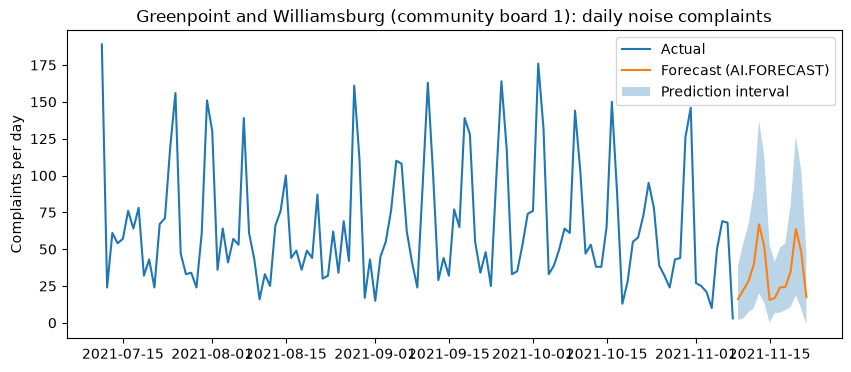

,day,forecast_value,prediction_interval_lower_bound,prediction_interval_upper_bound
0,2021-11-09,16.036045,1.915820,38.572653
1,2021-11-10,22.293255,2.915156,54.099611
2,2021-11-11,28.319988,7.222693,66.892443
3,2021-11-12,39.559578,9.836700,89.542566
4,2021-11-13,66.874954,19.948309,137.228819
5,2021-11-14,51.523102,13.629140,113.132856
6,2021-11-15,15.467953,0.196769,52.736771
7,2021-11-16,16.862427,6.634382,41.332361
8,2021-11-17,24.116268,6.938275,51.095900
9,2021-11-18,24.286465,8.646889,54.041395


In [26]:
import matplotlib.pyplot as plt

history = run_sql(f"""
SELECT created_day AS day, COUNT(*) AS complaints
FROM {T_VIEW}
WHERE complaint_type LIKE 'Noise%'
  AND community_board = '01 BROOKLYN'
  AND created_day >= DATE_SUB((SELECT MAX(created_day) FROM {T_VIEW}), INTERVAL 120 DAY)
GROUP BY day
ORDER BY day
""")

forecast = run_sql(f"""
SELECT
  DATE(forecast_timestamp) AS day,
  forecast_value,
  prediction_interval_lower_bound,
  prediction_interval_upper_bound
FROM AI.FORECAST(
  (
    SELECT created_day, COUNT(*) AS complaints
    FROM {T_VIEW}
    WHERE complaint_type LIKE 'Noise%'
      AND community_board = '01 BROOKLYN'
    GROUP BY created_day
  ),
  data_col => 'complaints',
  timestamp_col => 'created_day',
  horizon => 14)
ORDER BY day
""")

days = pd.to_datetime(forecast["day"].astype(str))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    pd.to_datetime(history["day"].astype(str)),
    history["complaints"].astype(float),
    label="Actual",
)
ax.plot(days, forecast["forecast_value"], label="Forecast (AI.FORECAST)")
ax.fill_between(
    days,
    forecast["prediction_interval_lower_bound"],
    forecast["prediction_interval_upper_bound"],
    alpha=0.3,
    label="Prediction interval",
)
ax.set_title("Greenpoint and Williamsburg (community board 1): daily noise complaints")
ax.set_ylabel("Complaints per day")
ax.legend()
plt.show()
forecast

## Step 3: Create a data agent with the Conversational Analytics API

A *data agent* combines your data with the context it needs to answer questions well:

- **Knowledge source:** the view from Step 2d, plus a table description and notes on key columns.
- **Instructions:** a few rules, written in the YAML structure that the API docs recommend.
- **Glossary terms:** business terms such as *no-action closure* and *heat season*.
- **Verified queries:** questions paired with SQL that you trust. When a question matches one, the agent can run your SQL directly instead of writing new SQL. A parameterized verified query matches any value, such as any neighborhood.

You can build the same agent in the BigQuery Studio UI (**Agents** > **Agent Catalog** > **New agent**). Building it with the API gives you code that you can review and version.

In [27]:
from google.api_core import exceptions
from google.api_core.client_options import ClientOptions
from google.cloud import geminidataanalytics_v1 as gda
from google.protobuf import field_mask_pb2


def ca_endpoint(location):
    """Returns the Conversational Analytics API endpoint for a location."""
    if location == "global":
        return "geminidataanalytics.googleapis.com"
    if "-" in location:  # A region, such as us-east4.
        return f"geminidataanalytics-{location}.googleapis.com"
    return f"geminidataanalytics.{location}.rep.googleapis.com"  # A multi-region.


client_options = ClientOptions(api_endpoint=ca_endpoint(AGENT_LOCATION))
agent_client = gda.DataAgentServiceClient(client_options=client_options)
chat_client = gda.DataChatServiceClient(client_options=client_options)

PARENT = f"projects/{PROJECT_ID}/locations/{AGENT_LOCATION}"
AGENT_NAME = f"{PARENT}/dataAgents/{AGENT_ID}"
print(AGENT_NAME)

projects/lakehouse-demos/locations/global/dataAgents/brooklyn-311-analyst


### Define the agent's context

Most of the context lives in structured fields: the table and column descriptions, glossary terms, and verified queries. The instructions cover everything else. Notice that a parameterized verified query uses `{neighborhood}` in the question and `@neighborhood` in the SQL.

In [28]:
view_ref = gda.BigQueryTableReference(
    project_id=PROJECT_ID,
    dataset_id=DATASET,
    table_id="brooklyn_311_enriched",
    schema=gda.Schema(
        description=(
            "One row per NYC 311 service request in Brooklyn, January 2019 to "
            "November 2021, with neighborhood names and an AI-classified outcome."
        ),
        synonyms=["311 requests", "service requests", "complaints"],
        tags=["NYC Open Data", "311", "Brooklyn"],
        fields=[
            gda.Field(
                name="outcome",
                description=(
                    "How the request ended, classified from resolution_description "
                    "with AI.CLASSIFY. Values: Action taken, No violation found, "
                    "Gone on arrival, Could not access, Duplicate, Referred "
                    "elsewhere, Pending or informational, Other, Unknown."
                ),
                synonyms=["result", "how it ended"],
            ),
            gda.Field(
                name="neighborhoods",
                description=(
                    "Comma-separated neighborhoods that the community board covers. "
                    "Filter with LIKE, for example neighborhoods LIKE '%Bushwick%'."
                ),
                synonyms=["neighborhood", "area"],
            ),
            gda.Field(
                name="created_day",
                description="Date the request was created. Use it for daily trends and forecasts.",
                synonyms=["date", "day"],
            ),
            gda.Field(
                name="hours_to_close",
                description="Hours from creation to closure. Use the median for a typical response time.",
                synonyms=["response time", "time to close"],
            ),
        ],
    ),
)

SYSTEM_INSTRUCTION = """
- system_instruction: >-
    You are a civic data analyst for Brooklyn, New York. You answer questions
    about NYC 311 service requests: what residents complain about, where, how
    fast city agencies respond, and how complaints end. Keep answers short
    (under 120 words) and lead with the numbers.
- additional_descriptions:
  - text: >-
      The data covers Brooklyn 311 requests from January 2019 to early
      November 2021. If someone asks about recent data or "last month", use
      the latest month in the data and say so.
  - text: >-
      When a user names a neighborhood, such as Williamsburg, Bed-Stuy, or
      Park Slope, filter with neighborhoods LIKE '%<name>%'.
  - text: A complaint is one service request. Count unique_key.
  - text: Use line charts for trends over time and bar charts for rankings.
  - text: >-
      For forecasts, aggregate to daily counts by created_day and use the
      AI.FORECAST table function.
"""

GLOSSARY = [
    gda.GlossaryTerm(
        display_name="No-action closure",
        description=(
            "A request that ended without action: outcome IN ('No violation "
            "found', 'Gone on arrival', 'Could not access')."
        ),
        labels=["closed without action", "no action taken"],
    ),
    gda.GlossaryTerm(
        display_name="Heat season",
        description=(
            "NYC heat season: October 1 through May 31. The last full heat season "
            "in the data runs from October 1, 2020 to May 31, 2021."
        ),
        labels=["heating season", "winter heat"],
    ),
    gda.GlossaryTerm(
        display_name="Noise complaints",
        description="Requests where complaint_type LIKE 'Noise%'.",
        labels=["noise", "loud music", "loud party"],
    ),
    gda.GlossaryTerm(
        display_name="Response time",
        description="hours_to_close. Use the median for a typical response time.",
        labels=["time to close", "resolution time"],
    ),
    gda.GlossaryTerm(
        display_name="Bed-Stuy",
        description="Bedford-Stuyvesant, covered by community board 03 BROOKLYN.",
        labels=["Bedford-Stuyvesant", "BedStuy"],
    ),
]

EXAMPLE_QUERIES = [
    gda.ExampleQuery(
        natural_language_question="How do complaints end in {neighborhood}?",
        sql_query=f"""
SELECT
  outcome,
  COUNT(*) AS complaints,
  ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_complaints
FROM {T_VIEW}
WHERE neighborhoods LIKE CONCAT('%', @neighborhood, '%')
GROUP BY outcome
ORDER BY complaints DESC
""",
        parameters=[
            gda.QueryParameter(
                name="neighborhood",
                data_type="STRING",
                description="A Brooklyn neighborhood name, such as Bushwick or Park Slope.",
            )
        ],
    ),
    gda.ExampleQuery(
        natural_language_question="What is the median response time by agency?",
        sql_query=f"""
SELECT
  agency,
  agency_name,
  COUNT(*) AS complaints,
  APPROX_QUANTILES(hours_to_close, 100)[OFFSET(50)] AS median_hours_to_close
FROM {T_VIEW}
WHERE closed_date IS NOT NULL AND hours_to_close >= 0
GROUP BY agency, agency_name
HAVING complaints >= 1000
ORDER BY median_hours_to_close
""",
    ),
    gda.ExampleQuery(
        natural_language_question="Forecast daily noise complaints in Brooklyn for the next 14 days.",
        sql_query=f"""
SELECT *
FROM AI.FORECAST(
  (
    SELECT created_day, COUNT(*) AS complaints
    FROM {T_VIEW}
    WHERE complaint_type LIKE 'Noise%'
    GROUP BY created_day
  ),
  data_col => 'complaints',
  timestamp_col => 'created_day',
  horizon => 14)
""",
    ),
]

context = gda.Context(
    system_instruction=SYSTEM_INSTRUCTION,
    datasource_references=gda.DatasourceReferences(
        bq=gda.BigQueryTableReferences(table_references=[view_ref])
    ),
    glossary_terms=GLOSSARY,
    example_queries=EXAMPLE_QUERIES,
    # Guardrail: each query that the agent runs can bill at most 10 GiB.
    options=gda.ConversationOptions(
        datasource=gda.DatasourceOptions(big_query_max_billed_bytes=10 * 1024**3)
    ),
)

### Create the agent

If the agent already exists (for example, because you ran this cell before), the cell updates it instead.

In [29]:
agent = gda.DataAgent(
    display_name="Brooklyn 311 Analyst",
    description=(
        "Answers questions about NYC 311 service requests in Brooklyn (2019 to "
        "November 2021): what people complain about, where, how fast agencies "
        "respond, and how complaints end."
    ),
    data_analytics_agent=gda.DataAnalyticsAgent(published_context=context),
)

try:
    agent = agent_client.create_data_agent_sync(
        request=gda.CreateDataAgentRequest(
            parent=PARENT, data_agent_id=AGENT_ID, data_agent=agent
        )
    )
    print(f"Created {agent.name}")
except exceptions.AlreadyExists:
    agent.name = AGENT_NAME
    agent = agent_client.update_data_agent_sync(
        request=gda.UpdateDataAgentRequest(
            data_agent=agent,
            update_mask=field_mask_pb2.FieldMask(
                paths=[
                    "display_name",
                    "description",
                    "data_analytics_agent.published_context",
                ]
            ),
        )
    )
    print(f"Updated {agent.name}")

Updated projects/lakehouse-demos/locations/global/dataAgents/brooklyn-311-analyst


## Step 4: Chat with your agent

`ask()` streams the agent's work as it happens: its progress, the SQL it writes, the data it gets back, a chart, and the final answer. Use `follow_up=True` to keep the earlier turns as context, and `show_thoughts=False` for shorter output.

In [30]:
import altair as alt
from IPython.display import Markdown, display

TextType = gda.TextMessage.TextType
conversation = []  # Message history, so that follow-up questions have context.


def _to_dataframe(result):
    """Converts a data result from the agent into a DataFrame."""
    rows = type(result).to_dict(result).get("data", [])
    columns = [field.name for field in result.schema.fields]
    df = pd.DataFrame(rows, columns=columns or None)
    for column in df.columns:  # Values arrive as strings, so convert numbers.
        try:
            df[column] = pd.to_numeric(df[column])
        except (ValueError, TypeError):
            pass
    return df


def _show_chart(result):
    """Renders the Vega-Lite chart that the agent generated."""
    spec = type(result).to_dict(result).get("vega_config")
    if not spec:
        return
    # Pick the Altair class that matches the top-level chart type.
    chart_types = {
        "layer": alt.LayerChart,
        "hconcat": alt.HConcatChart,
        "vconcat": alt.VConcatChart,
        "concat": alt.ConcatChart,
        "facet": alt.FacetChart,
        "repeat": alt.RepeatChart,
    }
    chart_type = next((t for key, t in chart_types.items() if key in spec), alt.Chart)
    try:
        chart_type.from_dict(spec).display()
    except Exception as e:  # pylint: disable=broad-exception-caught
        print(f"(The agent made a chart, but Altair couldn't render it: {e})")


def ask(question, follow_up=False, show_thoughts=True):
    """Asks the data agent a question and shows its work as it streams in."""
    if not follow_up:
        conversation.clear()
    conversation.append(gda.Message(user_message=gda.UserMessage(text=question)))
    request = gda.ChatRequest(
        parent=PARENT,
        messages=conversation,
        data_agent_context=gda.DataAgentContext(data_agent=AGENT_NAME),
    )
    display(Markdown(f"**You:** {question}"))
    context_used, follow_ups = set(), []
    for message in chat_client.chat(request=request, timeout=300):
        conversation.append(message)
        if "system_message" not in message:
            continue
        reply = message.system_message
        for source in reply.citation.sources:
            if "glossary_term" in source:
                context_used.add(f"glossary term '{source.glossary_term.display_name}'")
            elif "example_query" in source:
                question_text = source.example_query.natural_language_question
                context_used.add(f"verified query '{question_text}'")
        if "text" in reply:
            if reply.text.text_type == TextType.FINAL_RESPONSE:
                display(Markdown("".join(reply.text.parts)))
            elif reply.text.text_type == TextType.FOLLOWUP_QUESTIONS:
                follow_ups.extend(reply.text.parts)
            elif show_thoughts:
                for part in reply.text.parts:
                    print(f"Thinking: {part}")
        elif "data" in reply:
            data = reply.data
            if "matched_query" in data:
                matched = data.matched_query
                values = {p.name: p.value for p in matched.query_parameter_values}
                with_values = f" with {values}" if values else ""
                print(
                    "Matched verified query: "
                    f"{matched.example_query.natural_language_question}{with_values}"
                )
            elif "generated_sql" in data:
                display(Markdown(f"```sql\n{data.generated_sql}\n```"))
            elif "result" in data:
                display(_to_dataframe(data.result).head(20))
        elif "chart" in reply and "result" in reply.chart:
            _show_chart(reply.chart.result)
        elif "error" in reply:
            print(f"Agent error (the agent may recover and retry): {reply.error.text}")
    if context_used:
        print("Context the agent cited: " + ", ".join(sorted(context_used)))
    if follow_ups:
        print("Suggested follow-ups:\n- " + "\n- ".join(follow_ups))

This question uses a glossary term (*no-action closure*) and a neighborhood name. In the SQL, look for an `outcome IN (...)` filter that comes from the glossary, and a `neighborhoods LIKE` filter that comes from the instructions.

In [31]:
ask("Which complaint types in Williamsburg most often end in a no-action closure?")

**You:** Which complaint types in Williamsburg most often end in a no-action closure?

Thinking: Analyzing context
Thinking: Retrieving context for 1 table.
Thinking: Context retrieved
Thinking: Retrieved context for 1 table.
Thinking: Running a query
Thinking: SELECT complaint_type,
       COUNTIF(outcome IN ('No violation found', 'Gone on arrival', 'Could not access')) AS no_action_closures,
       COUNT(*) AS total_complaints,
       ROUND(100.0 * COUNTIF(outcome IN ('No violation found', 'Gone on arrival', 'Could not access')) / COUNT(*), 1) AS no_action_pct
FROM `lakehouse-demos.bk_data.brooklyn_311_enriched`
WHERE neighborhoods LIKE '%Williamsburg%'
GROUP BY complaint_type
HAVING total_complaints >= 50
ORDER BY no_action_pct DESC,
         no_action_closures DESC
LIMIT 10
Thinking: Query execution completed
Thinking: Query returned 10 rows in 3.53s.


I filtered for complaint types with at least 50 total requests in Williamsburg to focus on meaningful rates.

In Williamsburg, **COVID-19 Non-essential Construction** has the highest rate of no-action closures (96.4%), followed by **Other Enforcement** (86.3%), **Snow** (86.2%), and **Missed Collection (All Materials)** (84.1%, with 3,024 no-action closures out of 3,594 requests).

```sql
SELECT complaint_type,
       COUNTIF(outcome IN ('No violation found', 'Gone on arrival', 'Could not access')) AS no_action_closures,
       COUNT(*) AS total_complaints,
       ROUND(100.0 * COUNTIF(outcome IN ('No violation found', 'Gone on arrival', 'Could not access')) / COUNT(*), 1) AS no_action_pct
FROM `lakehouse-demos.bk_data.brooklyn_311_enriched`
WHERE neighborhoods LIKE '%Williamsburg%'
GROUP BY complaint_type
HAVING total_complaints >= 50
ORDER BY no_action_pct DESC,
         no_action_closures DESC
LIMIT 10
```

,complaint_type,no_action_closures,total_complaints,no_action_pct
0,COVID-19 Non-essential Construction,396.0,411.0,96.4
1,Other Enforcement,201.0,233.0,86.3
2,Snow,301.0,349.0,86.2
3,Missed Collection (All Materials),3024.0,3594.0,84.1
4,Dirty Conditions,2123.0,2551.0,83.2
5,Emergency Response Team (ERT),450.0,541.0,83.2
6,Animal Abuse,64.0,80.0,80.0
7,ELECTRIC,683.0,861.0,79.3
8,Urinating in Public,46.0,59.0,78.0
9,Electrical,76.0,98.0,77.6


```sql
SELECT complaint_type,
       COUNTIF(outcome IN ('No violation found', 'Gone on arrival', 'Could not access')) AS no_action_closures,
       COUNT(*) AS total_complaints,
       ROUND(100.0 * COUNTIF(outcome IN ('No violation found', 'Gone on arrival', 'Could not access')) / COUNT(*), 1) AS no_action_pct
FROM `lakehouse-demos.bk_data.brooklyn_311_enriched`
WHERE neighborhoods LIKE '%Williamsburg%'
GROUP BY complaint_type
HAVING total_complaints >= 50
ORDER BY no_action_pct DESC,
         no_action_closures DESC
LIMIT 10
```

alt.Chart(...)

### High Volume Sanitation Impact
While enforcement and construction categories have the highest proportion of no-action resolutions, sanitation issues like **Missed Collection** and **Dirty Conditions** account for the largest sheer volume of unaddressed complaints, combining for over 5,100 no-action closures.

Context the agent cited: glossary term 'No-action closure'
Suggested follow-ups:
- What are the most common complaint types overall in Williamsburg?
- How does the no-action closure rate in Williamsburg compare to Greenpoint?
- What is the median response time for noise complaints in Williamsburg?


This question matches the parameterized verified query, so the agent can run your SQL with `neighborhood` set to Bushwick. Look for the "Matched verified query" line.

In [32]:
ask("How do complaints end in Bushwick?")

**You:** How do complaints end in Bushwick?

Thinking: Analyzing context
Thinking: Retrieving context for 1 table.
Thinking: Context retrieved
Thinking: Retrieved context for 1 table.
Thinking: Matched a verified query
Thinking: SELECT outcome,
       COUNT(*) AS complaints,
       ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_complaints
FROM `lakehouse-demos.bk_data.brooklyn_311_enriched`
WHERE neighborhoods LIKE CONCAT('%', @neighborhood, '%')
GROUP BY outcome
ORDER BY complaints DESC
Thinking: Running a query
Thinking: SELECT outcome,
       COUNT(*) AS complaints,
       ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_complaints
FROM `lakehouse-demos.bk_data.brooklyn_311_enriched`
WHERE neighborhoods LIKE CONCAT('%', @neighborhood, '%')
GROUP BY outcome
ORDER BY complaints DESC
Thinking: Query execution completed
Thinking: Query returned 9 rows in 3.26s.
Matched verified query: How do complaints end in {neighborhood}? with {'neighborhood': 'Bushwick'}


,outcome,complaints,pct_of_complaints
0,No violation found,49619.0,39.1
1,Action taken,38293.0,30.2
2,Could not access,12579.0,9.9
3,Pending or informational,11096.0,8.7
4,Gone on arrival,6245.0,4.9
5,Unknown,3927.0,3.1
6,Duplicate,3231.0,2.5
7,Referred elsewhere,1682.0,1.3
8,Other,235.0,0.2


In Bushwick, the most common complaint outcomes are "No violation found" (39.1%) and "Action taken" (30.2%), followed by "Could not access" (9.9%) and "Pending or informational" (8.7%). Less frequent outcomes include "Gone on arrival" (4.9%), "Unknown" (3.1%), "Duplicate" (2.5%), "Referred elsewhere" (1.3%), and "Other" (0.2%).

Matched verified query: How do complaints end in {neighborhood}? with {'neighborhood': 'Bushwick'}


alt.Chart(...)

Context the agent cited: verified query 'How do complaints end in {neighborhood}?'
Suggested follow-ups:
- Analyze the key drivers behind why complaints result in no violations found in Bushwick.
- Forecast monthly complaint volumes for Bushwick over the next year.


A follow-up question. Because `follow_up=True` sends the earlier turns too, the agent knows what "that" refers to.

In [37]:
ask("How does that compare with Park Slope?", follow_up=True)

**You:** How does that compare with Park Slope?

Thinking: Analyzing context
Thinking: Retrieving context for 1 table.
Thinking: Context retrieved
Thinking: Retrieved context for 1 table.
Thinking: Matched a verified query
Thinking: SELECT outcome,
       COUNT(*) AS complaints,
       ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_complaints
FROM `lakehouse-demos.bk_data.brooklyn_311_enriched`
WHERE neighborhoods LIKE CONCAT('%', @neighborhood, '%')
GROUP BY outcome
ORDER BY complaints DESC
Thinking: Running a query
Thinking: SELECT outcome,
       COUNT(*) AS complaints,
       ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_complaints
FROM `lakehouse-demos.bk_data.brooklyn_311_enriched`
WHERE neighborhoods LIKE CONCAT('%', @neighborhood, '%')
GROUP BY outcome
ORDER BY complaints DESC
Thinking: Query execution completed
Thinking: Query returned 9 rows in 3.45s.
Matched verified query: How do complaints end in {neighborhood}? with {'neighborhood': 'Park Slope'}


,outcome,complaints,pct_of_complaints
0,No violation found,33490.0,35.8
1,Action taken,25729.0,27.5
2,Pending or informational,14202.0,15.2
3,Unknown,7587.0,8.1
4,Could not access,3439.0,3.7
5,Referred elsewhere,3275.0,3.5
6,Duplicate,3078.0,3.3
7,Gone on arrival,2537.0,2.7
8,Other,129.0,0.1


In Park Slope, the most common complaint outcome is "No violation found" (35.8%), followed by "Action taken" (27.5%) and "Pending or informational" (15.2%), with all other outcomes accounting for less than 10% each.

Matched verified query: How do complaints end in {neighborhood}? with {'neighborhood': 'Park Slope'}


alt.Chart(...)

Context the agent cited: verified query 'How do complaints end in {neighborhood}?'
Suggested follow-ups:
- Identify key drivers of complaint outcomes in Park Slope using AI.KEY_DRIVERS.
- Compare complaint outcomes in Park Slope with Williamsburg using a side-by-side breakdown.
- Forecast monthly complaint volumes for Park Slope using AI.FORECAST.


Agents can call AI functions too. Look for `AI.FORECAST` in the generated SQL.

In [38]:
ask("Forecast noise complaints in Bushwick for the next two weeks.")

**You:** Forecast noise complaints in Bushwick for the next two weeks.

Thinking: Analyzing context
Thinking: Retrieving context for 1 table.
Thinking: Context retrieved
Thinking: Retrieved context for 1 table.
Thinking: Running a query
Thinking: WITH daily_bushwick_noise AS
  (SELECT created_day,
          COUNT(unique_key) AS complaints
   FROM `lakehouse-demos.bk_data.brooklyn_311_enriched`
   WHERE complaint_type LIKE 'Noise%'
     AND neighborhoods LIKE '%Bushwick%'
     AND created_day < CURRENT_DATE()
   GROUP BY created_day)
SELECT forecast_timestamp,
       ROUND(forecast_value, 1) AS forecast_complaints,
       ROUND(prediction_interval_lower_bound, 1) AS lower_bound,
       ROUND(prediction_interval_upper_bound, 1) AS upper_bound
FROM AI.FORECAST(TABLE daily_bushwick_noise, data_col => 'complaints', timestamp_col => 'created_day', horizon => 14, model => 'TimesFM 2.5')
ORDER BY forecast_timestamp ASC
Thinking: Query execution completed
Thinking: Query returned 14 rows in 4.84s.


Here is the 14-day daily forecast for noise complaints in Bushwick generated using AI.FORECAST. Daily complaints are projected to range from approximately 13.1 to 39.2 per day, peaking notably over weekend dates (e.g., November 13–14 and November 20–21).

```sql
WITH daily_bushwick_noise AS
  (SELECT created_day,
          COUNT(unique_key) AS complaints
   FROM `lakehouse-demos.bk_data.brooklyn_311_enriched`
   WHERE complaint_type LIKE 'Noise%'
     AND neighborhoods LIKE '%Bushwick%'
     AND created_day < CURRENT_DATE()
   GROUP BY created_day)
SELECT forecast_timestamp,
       ROUND(forecast_value, 1) AS forecast_complaints,
       ROUND(prediction_interval_lower_bound, 1) AS lower_bound,
       ROUND(prediction_interval_upper_bound, 1) AS upper_bound
FROM AI.FORECAST(TABLE daily_bushwick_noise, data_col => 'complaints', timestamp_col => 'created_day', horizon => 14, model => 'TimesFM 2.5')
ORDER BY forecast_timestamp ASC
```

,forecast_timestamp,forecast_complaints,lower_bound,upper_bound
0,2021-11-09 00:00:00,14.3,0.7,35.9
1,2021-11-10 00:00:00,13.1,-2.8,37.5
2,2021-11-11 00:00:00,18.4,4.5,45.2
3,2021-11-12 00:00:00,25.6,8.9,56.4
4,2021-11-13 00:00:00,39.2,10.8,84.1
5,2021-11-14 00:00:00,34.9,9.9,76.8
6,2021-11-15 00:00:00,15.6,3.3,45.7
7,2021-11-16 00:00:00,15.4,7.0,36.1
8,2021-11-17 00:00:00,15.5,2.6,39.8
9,2021-11-18 00:00:00,17.0,4.6,41.8


```sql
WITH daily_bushwick_noise AS
  (SELECT created_day,
          COUNT(unique_key) AS complaints
   FROM `lakehouse-demos.bk_data.brooklyn_311_enriched`
   WHERE complaint_type LIKE 'Noise%'
     AND neighborhoods LIKE '%Bushwick%'
     AND created_day < CURRENT_DATE()
   GROUP BY created_day)
SELECT forecast_timestamp,
       ROUND(forecast_value, 1) AS forecast_complaints,
       ROUND(prediction_interval_lower_bound, 1) AS lower_bound,
       ROUND(prediction_interval_upper_bound, 1) AS upper_bound
FROM AI.FORECAST(TABLE daily_bushwick_noise, data_col => 'complaints', timestamp_col => 'created_day', horizon => 14, model => 'TimesFM 2.5')
ORDER BY forecast_timestamp ASC
```

alt.LayerChart(...)

### Weekly Seasonality Spike
Bushwick noise complaints show strong weekend peaks (reaching ~35–39 complaints/day on Saturdays and Sundays) compared to weekday baselines of ~13–18 complaints/day.

Context the agent cited: glossary term 'Noise complaints', verified query 'Forecast daily noise complaints in Brooklyn for the next 14 days.'
Suggested follow-ups:
- Forecast noise complaints for Williamsburg over the next 14 days.
- What are the key drivers behind noise complaints in Bushwick?
- Show the trend of noise complaints in Bushwick over the past year.


### Your turn

Ask your own question. For ideas: response times by agency, the noisiest month of 2021, or heat complaints during the last heat season.

In [39]:
QUESTION = "Compare heat complaints in Bed-Stuy and Park Slope during the last heat season."  # @param {type: "string"}
ask(QUESTION)

**You:** Compare heat complaints in Bed-Stuy and Park Slope during the last heat season.

Thinking: Analyzing context
Thinking: Retrieving context for 1 table.
Thinking: Context retrieved
Thinking: Retrieved context for 1 table.
Thinking: Running a query
Thinking: SELECT CASE
           WHEN neighborhoods LIKE '%Bedford-Stuyvesant%'
                OR neighborhoods LIKE '%Bed-Stuy%' THEN 'Bed-Stuy'
           WHEN neighborhoods LIKE '%Park Slope%' THEN 'Park Slope'
       END AS neighborhood,
       COUNT(unique_key) AS total_heat_complaints,
       APPROX_QUANTILES(hours_to_close, 100)[OFFSET(50)] AS median_hours_to_close
FROM `lakehouse-demos.bk_data.brooklyn_311_enriched`
WHERE (complaint_type LIKE '%HEAT%'
       OR complaint_type LIKE '%Heat%')
  AND created_day BETWEEN DATE '2020-10-01' AND DATE '2021-05-31'
  AND (neighborhoods LIKE '%Bedford-Stuyvesant%'
       OR neighborhoods LIKE '%Bed-Stuy%'
       OR neighborhoods LIKE '%Park Slope%')
GROUP BY neighborhood
ORDER BY total_heat_complaints DESC
Thinking: Query execution completed
Thinking: Query returned 2 rows in

During the last full heat season (October 1, 2020 – May 31, 2021), Bed-Stuy had **3,905** heat complaints with a median resolution time of **51 hours**, compared to **887** complaints and a **58-hour** median resolution time in Park Slope.

```sql
SELECT CASE
           WHEN neighborhoods LIKE '%Bedford-Stuyvesant%'
                OR neighborhoods LIKE '%Bed-Stuy%' THEN 'Bed-Stuy'
           WHEN neighborhoods LIKE '%Park Slope%' THEN 'Park Slope'
       END AS neighborhood,
       COUNT(unique_key) AS total_heat_complaints,
       APPROX_QUANTILES(hours_to_close, 100)[OFFSET(50)] AS median_hours_to_close
FROM `lakehouse-demos.bk_data.brooklyn_311_enriched`
WHERE (complaint_type LIKE '%HEAT%'
       OR complaint_type LIKE '%Heat%')
  AND created_day BETWEEN DATE '2020-10-01' AND DATE '2021-05-31'
  AND (neighborhoods LIKE '%Bedford-Stuyvesant%'
       OR neighborhoods LIKE '%Bed-Stuy%'
       OR neighborhoods LIKE '%Park Slope%')
GROUP BY neighborhood
ORDER BY total_heat_complaints DESC
```

,neighborhood,total_heat_complaints,median_hours_to_close
0,Bed-Stuy,3905.0,51.0
1,Park Slope,887.0,58.0


Context the agent cited: glossary term 'Bed-Stuy', glossary term 'Heat season', glossary term 'Response time'
Suggested follow-ups:
- Compare the resolution outcomes of heat complaints between Bed-Stuy and Park Slope.
- Forecast daily heat complaints for Bed-Stuy over the next 14 days.
- Analyze monthly heat complaint trends for Bed-Stuy and Park Slope across all years.


## Step 5: Publish your agent to Gemini Enterprise

Gemini Enterprise is where many people already do their work, so publishing your agent there lets them use it without a new app. You publish from the agent editor in BigQuery Studio. The recommended path uses Agent Registry, which needs an Agent Gateway whose registry binding matches your agent's region (US, EU, or Global). Your Gemini Enterprise admin sets that up.

1. In the Google Cloud console, go to BigQuery **Agents** > **Agent Catalog**, and open your agent. If the agent that you created with the API isn't listed, create one with **New agent**, using the settings that the next cell prints. Test it in the **Preview** pane, and then click **Save**.
2. Click **Publish** (or **Publish updates**). In the **Publishing channels** pane:
   - If BigQuery and Gemini Enterprise are in the same project, select **Register this agent** in the **Agent Registry** section.
   - If they're in different projects, click **Copy JSON** in the **Integrate via A2A** section, and send the agent card to your Gemini Enterprise admin.
3. Share the agent with the people who will use it. They need the Gemini Data Analytics Data Agent User role (`roles/geminidataanalytics.dataAgentUser`) and read access to the data.
4. A Gemini Enterprise admin opens the app, goes to **Agents** > **Add agent**, chooses **Agents from Agent Registry**, and adds your agent. For an agent card JSON from another project, the admin first registers the agent in Agent Registry, or uses **Custom agent via A2A** (Preview) instead. The admin then chooses **Default Google-managed credentials**, clicks **Finish**, and shares the agent.
5. In Gemini Enterprise, users find the agent in the **Agent Gallery**, or they `@mention` it in a chat. The first time, they complete a one-time sign-in.

For details, see [Publish a data agent in Gemini Enterprise](https://docs.cloud.google.com/bigquery/docs/create-data-agents#publish-agent-gemini-enterprise).

In [ ]:
print("Knowledge source:", T_VIEW.strip("`"))
print("\nInstructions:", SYSTEM_INSTRUCTION)
print("Glossary terms:")
for term in GLOSSARY:
    print(f"- {term.display_name}: {term.description} Synonyms: {', '.join(term.labels)}")
print("\nVerified queries. In BigQuery Studio, write a parameter as @name in the")
print("question, and add it (STRING) under Manage query parameters.")
for query in EXAMPLE_QUERIES:
    question = query.natural_language_question.replace("{neighborhood}", "@neighborhood")
    print(f"\nQuestion: {question}{query.sql_query}")

## Step 6 (bonus): Build on your agent with ADK

[Agent Development Kit (ADK)](https://adk.dev/) is an open-source framework for building agents in code. In this step, you build two small agents:

- A concierge agent that hands data questions to your data agent, by using ADK's data agent tools.
- A SQL agent that uses the BigQuery remote MCP server.

Both use Gemini through your Google Cloud project.

In [ ]:
import google.auth.transport.requests
from google.adk.agents import Agent
from google.adk.runners import Runner
from google.adk.sessions import InMemorySessionService
from google.genai import types
from IPython.display import Markdown, display

# Use Gemini through your Google Cloud project.
os.environ["GOOGLE_CLOUD_PROJECT"] = PROJECT_ID
os.environ["GOOGLE_CLOUD_LOCATION"] = "global"
os.environ["GOOGLE_GENAI_USE_ENTERPRISE"] = "true"
os.environ["GOOGLE_GENAI_USE_VERTEXAI"] = "true"  # The older name of the setting.

# The latest Gemini Flash model. If this alias isn't available to you, use a
# specific model version from the Gemini models list.
ADK_MODEL = "gemini-flash-latest"  # @param {type: "string"}

credentials, _ = google.auth.default()
if not credentials.valid:
    credentials.refresh(google.auth.transport.requests.Request())

session_service = InMemorySessionService()


async def chat(agent, question):
    """Sends one question to an ADK agent and shows its tool calls and answer."""
    async with Runner(
        agent=agent, app_name="devfest_demo", session_service=session_service
    ) as runner:
        session = await session_service.create_session(
            app_name="devfest_demo", user_id="attendee"
        )
        message = types.Content(role="user", parts=[types.Part(text=question)])
        display(Markdown(f"**You:** {question}"))
        async for event in runner.run_async(
            user_id="attendee", session_id=session.id, new_message=message
        ):
            for call in event.get_function_calls():
                print(f"[{event.author}] calls tool: {call.name}")
            if event.is_final_response() and event.content and event.content.parts:
                display(Markdown("".join(part.text or "" for part in event.content.parts)))

### 6a. A concierge agent that delegates to your data agent

`DataAgentToolset` gives an ADK agent tools to work with data agents. Here, the agent gets only the `ask_data_agent` tool, and its instruction tells it which data agent to ask.

In [ ]:
from google.adk.tools.data_agent import (
    DataAgentCredentialsConfig,
    DataAgentToolConfig,
    DataAgentToolset,
)

data_agent_tools = DataAgentToolset(
    credentials_config=DataAgentCredentialsConfig(credentials=credentials),
    data_agent_tool_config=DataAgentToolConfig(location=AGENT_LOCATION),
    tool_filter=["ask_data_agent"],
)

concierge = Agent(
    name="brooklyn_concierge",
    model=ADK_MODEL,
    description="Helps residents understand 311 complaints in Brooklyn.",
    instruction=(
        "You help people understand NYC 311 complaints in Brooklyn. For any "
        "question about the data, call ask_data_agent with "
        f"data_agent_name='{AGENT_NAME}', and pass the user's question as the "
        "query. Then answer in two or three friendly sentences that include the "
        "key numbers."
    ),
    tools=[data_agent_tools],
)

await chat(concierge, "Which Brooklyn neighborhood had the most noise complaints in 2021?")

### 6b. A SQL agent that uses the BigQuery remote MCP server

The BigQuery remote MCP server lets any MCP client explore datasets and run SQL. ADK connects to it with `McpToolset`. This agent gets only read-only tools: `execute_sql`, the one tool that can modify data, is left out on purpose.

In [ ]:
from google.adk.tools.mcp_tool.mcp_session_manager import StreamableHTTPConnectionParams
from google.adk.tools.mcp_tool.mcp_toolset import McpToolset


def bigquery_mcp_headers(readonly_context=None):
    """Adds an OAuth access token, and the project to bill, to each MCP request."""
    if not credentials.valid:
        credentials.refresh(google.auth.transport.requests.Request())
    return {
        "Authorization": f"Bearer {credentials.token}",
        "x-goog-user-project": PROJECT_ID,
    }


bigquery_mcp = McpToolset(
    connection_params=StreamableHTTPConnectionParams(
        url="https://bigquery.googleapis.com/mcp"
    ),
    tool_filter=["list_table_ids", "get_table_info", "execute_sql_readonly"],
    header_provider=bigquery_mcp_headers,
)

sql_agent = Agent(
    name="bigquery_mcp_agent",
    model=ADK_MODEL,
    instruction=(
        f"You answer questions with data in the BigQuery dataset {PROJECT_ID}.{DATASET}. "
        "Use the brooklyn_311_enriched view. Check the table schema before you "
        f"write SQL, and run queries with execute_sql_readonly in project {PROJECT_ID}. "
        "Show the SQL that you ran, and then the answer."
    ),
    tools=[bigquery_mcp],
)

await chat(sql_agent, "Which three ZIP codes had the most illegal parking complaints in 2021?")

### Use the BigQuery MCP server from other MCP clients

Any MCP client that supports remote servers, such as an IDE or a command-line agent, can use the same server:

- **Server URL:** `https://bigquery.googleapis.com/mcp`
- **Transport:** Streamable HTTP
- **Authentication:** your Google Cloud credentials, an OAuth client ID and secret, or an agent identity. The OAuth scope is `https://www.googleapis.com/auth/bigquery`.
- **Tools:** `list_dataset_ids`, `get_dataset_info`, `list_table_ids`, `get_table_info`, `execute_sql_readonly`, `execute_sql`, `get_query_results`, `get_job`, and `cancel_job`.
- **Limits:** results are capped at 3,000 rows, and queries time out after three minutes by default. `execute_sql` is the only tool that isn't read-only, and you can block it with an IAM deny policy.

The remote MCP server is enabled when you enable the BigQuery API. For details, see [Use the BigQuery MCP server](https://docs.cloud.google.com/bigquery/docs/use-bigquery-mcp).

> **Tip:** ADK also has a built-in BigQuery toolset (`BigQueryToolset` in `google.adk.integrations.bigquery`) that runs in your agent's process, with tools such as `execute_sql`, `forecast`, and `ask_data_insights`. See [ADK BigQuery tools](https://adk.dev/integrations/bigquery/).

## Troubleshooting

- **An API error right after you enable the APIs:** newly enabled APIs can take a few minutes to work everywhere. Wait, and then run the cell again.
- **`Permission denied` or `403` errors:** compare your roles with the table in **Before you begin**.
- **A model isn't found in Step 6:** set `ADK_MODEL` to a specific Gemini model version that's available in your project.
- **You deleted the agent and can't create it again:** set a new `AGENT_ID`.

## Clean up

To avoid charges, delete what you created: set the options to `True`, and then run the cell.

- If you published the agent to Gemini Enterprise, remove it there too.
- Deleted data agents are soft-deleted first. If you want to create the agent again right away, use a new `AGENT_ID`.

In [ ]:
DELETE_AGENT = False  # @param {type: "boolean"}
DELETE_DATASET = False  # @param {type: "boolean"}

if DELETE_AGENT:
    agent_client.delete_data_agent_sync(
        request=gda.DeleteDataAgentRequest(name=AGENT_NAME)
    )
    print(f"Deleted {AGENT_NAME}")
if DELETE_DATASET:
    bq.delete_dataset(f"{PROJECT_ID}.{DATASET}", delete_contents=True, not_found_ok=True)
    print(f"Deleted the dataset {PROJECT_ID}.{DATASET}")

## Learn more

- [Generative AI overview (AI functions in BigQuery)](https://docs.cloud.google.com/bigquery/docs/generative-ai-overview)
- [Control costs with token quotas](https://docs.cloud.google.com/bigquery/docs/control-genai-costs)
- [Conversational analytics overview](https://docs.cloud.google.com/bigquery/docs/conversational-analytics)
- [Create data agents](https://docs.cloud.google.com/bigquery/docs/create-data-agents)
- [Conversational Analytics API overview](https://docs.cloud.google.com/gemini/data-agents/conversational-analytics-api/overview)
- [Build a data agent with the Python SDK](https://docs.cloud.google.com/gemini/data-agents/conversational-analytics-api/build-agent-sdk)
- [Use the BigQuery MCP server](https://docs.cloud.google.com/bigquery/docs/use-bigquery-mcp)
- [ADK BigQuery tools](https://adk.dev/integrations/bigquery/) and [ADK data agent tools](https://adk.dev/integrations/data-agent/)

**Data attribution:** NYC 311 service requests, published by the City of New York on [NYC Open Data](https://opendata.cityofnewyork.us/), via the BigQuery public dataset `bigquery-public-data.new_york_311`.